# CAPSTONE PROJECT 1

## Working with NumPy Matrices — Multidimensional Data

## Introduction

This project analyses body-measurement data from the National Health and Nutrition Examination Survey (NHANES).

The analysis uses NumPy matrices to work with multidimensional data and Matplotlib to create visualisations. The project compares male and female body measurements, analyses weight distributions, calculates Body Mass Index (BMI), standardises measurements using z-scores, studies correlations between variables, and examines waist-to-height and waist-to-hip ratios.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
male = np.genfromtxt(
    "nhanes_adult_male_bmx_2020.csv",
    delimiter=",",
    skip_header=1
)

female = np.genfromtxt(
    "nhanes_adult_female_bmx_2020.csv",
    delimiter=",",
    skip_header=1
)

print("Male data shape:", male.shape)
print("Female data shape:", female.shape)

Male data shape: (4082, 7)
Female data shape: (4222, 7)


## 3. Weight Distributions

The weight distributions of female and male participants are visualised using histograms. The female weights are shown in the top subplot and the male weights are shown in the bottom subplot. The same x-axis limits are used for both plots so that the distributions can be compared fairly.

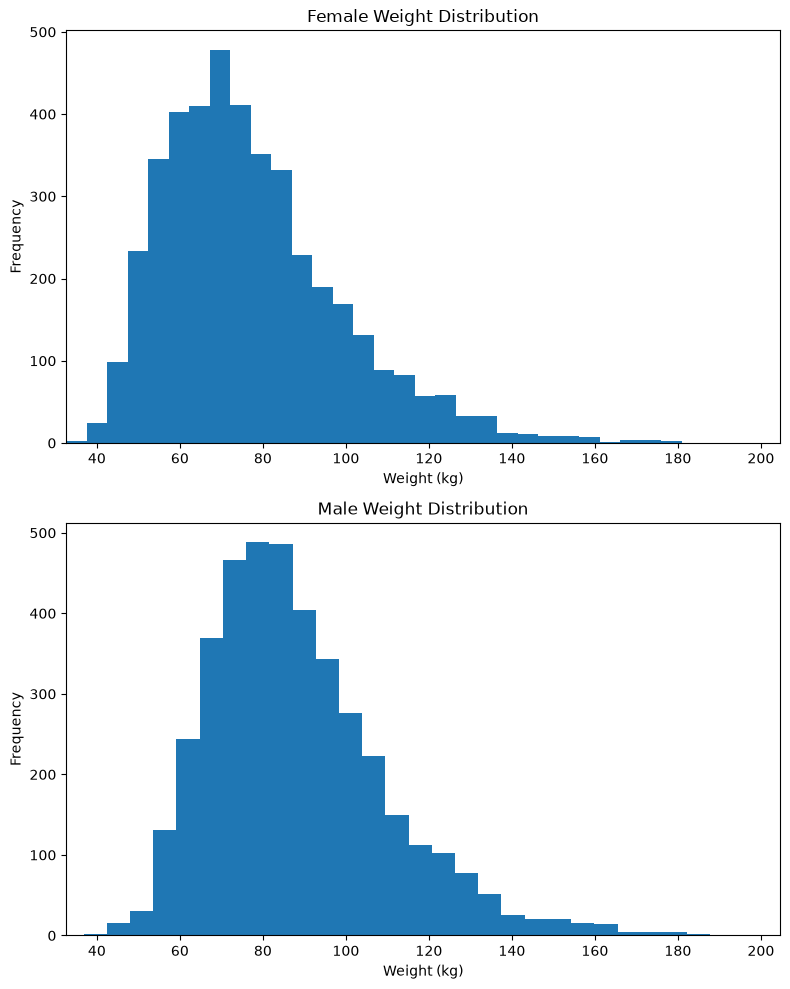

In [6]:
female_weights = female[:, 0]
male_weights = male[:, 0]

# Remove missing (NaN) weight values
female_weights = female_weights[~np.isnan(female_weights)]
male_weights = male_weights[~np.isnan(male_weights)]

# Find common x-axis limits
xmin = min(female_weights.min(), male_weights.min())
xmax = max(female_weights.max(), male_weights.max())

plt.figure(figsize=(8, 10))

# Female histogram
plt.subplot(2, 1, 1)
plt.hist(female_weights, bins=30)
plt.xlim(xmin, xmax)
plt.title("Female Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

# Male histogram
plt.subplot(2, 1, 2)
plt.hist(male_weights, bins=30)
plt.xlim(xmin, xmax)
plt.title("Male Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation

The histograms show the distribution of body weight among female and male participants. Both distributions are concentrated around the lower-to-middle range of the observed weights, with fewer participants at very high weights.

The distributions are not perfectly symmetrical and show a longer tail toward higher weights, indicating positive (right) skewness. The male and female distributions can be compared directly because both histograms use the same x-axis limits.

## 4. Comparing Male and Female Weights Using a Boxplot

A box-and-whisker plot is used to compare the distributions of male and female weights. The boxplot shows the median, the middle 50% of observations, the overall spread, and potential outliers in each distribution.

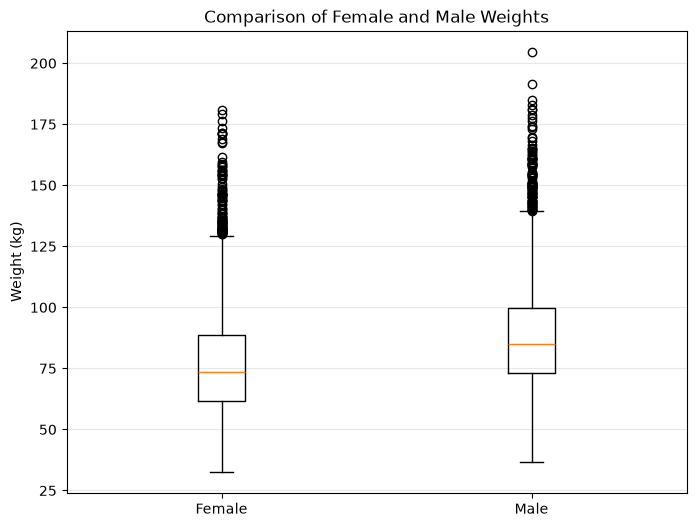

In [8]:
plt.figure(figsize=(8, 6))

plt.boxplot(
    [female_weights, male_weights],
    tick_labels=["Female", "Male"]
)

plt.title("Comparison of Female and Male Weights")
plt.ylabel("Weight (kg)")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Interpretation

The boxplot provides a direct comparison of the weight distributions for female and male participants. The median weight indicates the central value of each distribution, while the height of each box represents the spread of the middle 50% of observations.

The male and female groups show differences in their typical weights and overall spread. The points extending beyond the whiskers represent potential outliers, indicating participants with unusually high or low recorded weights compared with the rest of their group.

## 5. NumPy Matrix Operations

The male and female datasets are stored as NumPy matrices. Basic matrix operations are used to inspect their dimensions and compare the body-measurement data.

In [9]:
print("Male matrix dimensions:", male.shape)
print("Female matrix dimensions:", female.shape)

print("\nFirst 5 rows of male data:")
print(male[:5])

print("\nFirst 5 rows of female data:")
print(female[:5])

Male matrix dimensions: (4082, 7)
Female matrix dimensions: (4222, 7)

First 5 rows of male data:
[[  nan   nan   nan   nan   nan   nan   nan]
 [ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]
 [ 86.  167.8  39.5  38.4  29.  106.4 108.3]]

First 5 rows of female data:
[[  nan   nan   nan   nan   nan   nan   nan]
 [ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]
 [ 61.7 157.4  38.   34.7  29.  101.   90.5]]


In [10]:
print("Male matrix transpose shape:", male.T.shape)
print("Female matrix transpose shape:", female.T.shape)

print("\nMale column means:")
print(np.nanmean(male, axis=0))

print("\nFemale column means:")
print(np.nanmean(female, axis=0))

Male matrix transpose shape: (7, 4082)
Female matrix transpose shape: (7, 4222)

Male column means:
[ 88.364543   173.82702769  39.21504533  41.34123989  34.3341828
 104.49509924 101.78941436]

Female column means:
[ 77.40379057 160.13679223  36.0310353   37.15797204  32.71032931
 109.17837005  98.48810708]


## 6. Body Mass Index (BMI)

Body Mass Index (BMI) is calculated using weight and height. The height values in the dataset are given in centimetres, so they are converted to metres before calculating BMI.

In [11]:
male_height_m = male[:, 1] / 100
female_height_m = female[:, 1] / 100

male_weight = male[:, 0]
female_weight = female[:, 0]

male_bmi = male_weight / (male_height_m ** 2)
female_bmi = female_weight / (female_height_m ** 2)

male_bmi = male_bmi[~np.isnan(male_bmi)]
female_bmi = female_bmi[~np.isnan(female_bmi)]

print("Mean male BMI:", np.mean(male_bmi))
print("Mean female BMI:", np.mean(female_bmi))

Mean male BMI: 29.143143902641956
Mean female BMI: 30.10337881096128


### BMI Distribution

The BMI distributions of male and female participants are visualised using histograms. The distributions allow the typical BMI values and variation between the two groups to be compared.

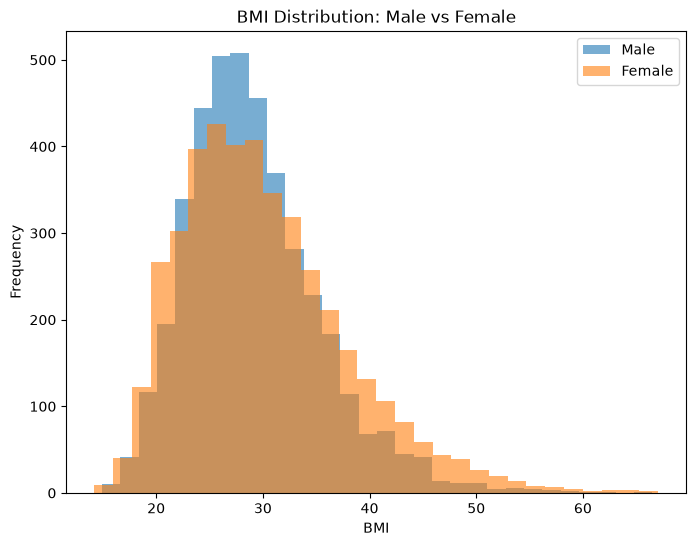

In [12]:
plt.figure(figsize=(8, 6))

plt.hist(male_bmi, bins=30, alpha=0.6, label="Male")
plt.hist(female_bmi, bins=30, alpha=0.6, label="Female")

plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("BMI Distribution: Male vs Female")
plt.legend()

plt.show()

### Interpretation

The mean BMI is approximately 29.14 for males and 30.10 for females. The histograms show the distribution of BMI values for both groups and allow their central tendencies and spread to be compared.

## 7. Standardising Measurements Using Z-Scores

Z-scores standardise measurements by expressing each value relative to the mean and standard deviation of its group. This allows measurements on different scales to be compared.

In [14]:
male_mean = np.nanmean(male, axis=0)
male_std = np.nanstd(male, axis=0)

female_mean = np.nanmean(female, axis=0)
female_std = np.nanstd(female, axis=0)

male_z = (male - male_mean) / male_std
female_z = (female - female_mean) / female_std

print("Male Z-score matrix shape:", male_z.shape)
print("Female Z-score matrix shape:", female_z.shape)

print("\nFirst 5 rows of male Z-scores:")
print(male_z[:5])

print("\nFirst 5 rows of female Z-scores:")
print(female_z[:5])

Male Z-score matrix shape: (4082, 7)
Female Z-score matrix shape: (4222, 7)

First 5 rows of male Z-scores:
[[        nan         nan         nan         nan         nan         nan
          nan]
 [ 0.48720705  1.10591976  1.14339753 -0.38613936  0.80788803  0.30342312
   1.12527144]
 [-0.65664058  1.35391391  0.77389142 -0.10615688 -0.86397174 -0.81857635
  -0.90632075]
 [ 0.71597658  1.49748947  3.19620928  0.82711806 -0.48780329  0.27066401
   0.47225967]
 [-0.11039498 -0.78666715  0.11699166 -0.91499516 -1.1147507   0.15600713
   0.3936564 ]]

First 5 rows of female Z-scores:
[[        nan         nan         nan         nan         nan         nan
          nan]
 [ 0.91429508  0.00895038 -0.56739463  1.13298804  0.55084546  1.08316157
   1.11578462]
 [ 0.63577599 -1.05306843 -1.07893145 -1.29349161  1.03221804  1.04475528
   0.265089  ]
 [-0.2044233   0.15055289  0.5835632   0.26194406 -0.1622991  -0.19064688
  -0.37293272]
 [-0.7289676  -0.38753664  0.83933161 -0.76464348 -0.661

### Interpretation

The Z-score transformation standardises each measurement relative to the mean and standard deviation of its group. A Z-score near 0 represents a value close to the group mean, while positive and negative Z-scores indicate values above and below the mean respectively.

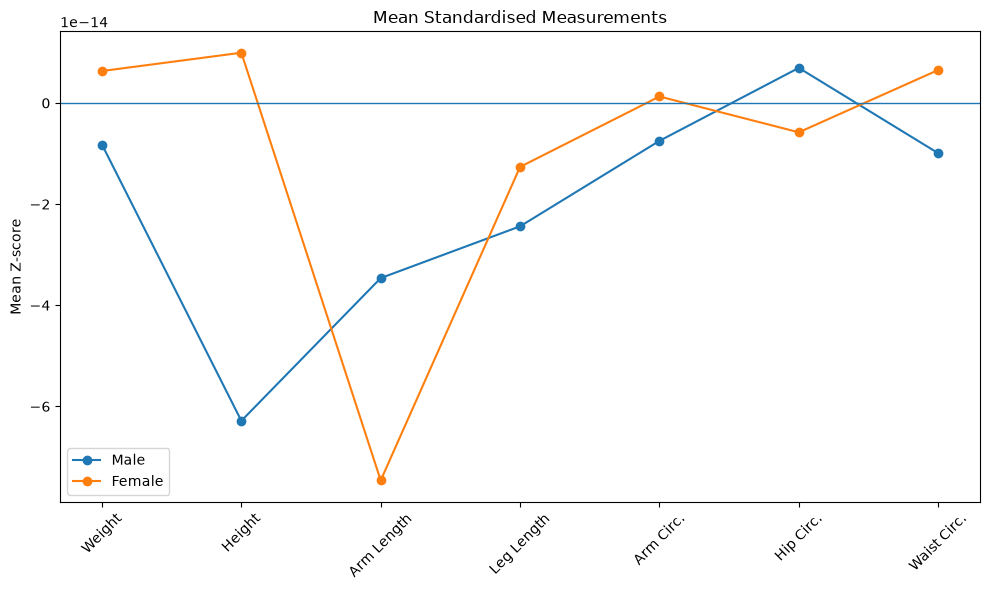

In [15]:
male_z_mean = np.nanmean(male_z, axis=0)
female_z_mean = np.nanmean(female_z, axis=0)

measurements = [
    "Weight",
    "Height",
    "Arm Length",
    "Leg Length",
    "Arm Circ.",
    "Hip Circ.",
    "Waist Circ."
]

x = np.arange(len(measurements))

plt.figure(figsize=(10, 6))

plt.plot(x, male_z_mean, marker="o", label="Male")
plt.plot(x, female_z_mean, marker="o", label="Female")

plt.xticks(x, measurements, rotation=45)
plt.ylabel("Mean Z-score")
plt.title("Mean Standardised Measurements")
plt.axhline(0, linewidth=1)
plt.legend()
plt.tight_layout()

plt.show()

In [17]:
# Remove rows containing NaN values
male_clean = male[~np.isnan(male).any(axis=1)]
female_clean = female[~np.isnan(female).any(axis=1)]

# Calculate correlation matrices
male_corr = np.corrcoef(male_clean, rowvar=False)
female_corr = np.corrcoef(female_clean, rowvar=False)

print("Male correlation matrix:")
print(male_corr)

print("\nFemale correlation matrix:")
print(female_corr)

Male correlation matrix:
[[1.         0.43415325 0.49153501 0.27645396 0.89314037 0.94190019
  0.89894646]
 [0.43415325 1.         0.72089904 0.69702341 0.26752474 0.30223617
  0.17573744]
 [0.49153501 0.72089904 1.         0.51370578 0.37554794 0.39972728
  0.3412585 ]
 [0.27645396 0.69702341 0.51370578 1.         0.21056336 0.1882287
  0.0250829 ]
 [0.89314037 0.26752474 0.37554794 0.21056336 1.         0.83566102
  0.78237004]
 [0.94190019 0.30223617 0.39972728 0.1882287  0.83566102 1.
  0.89469332]
 [0.89894646 0.17573744 0.3412585  0.0250829  0.78237004 0.89469332
  1.        ]]

Female correlation matrix:
[[ 1.          0.34549627  0.55156338  0.19318571  0.90538509  0.94655347
   0.90455038]
 [ 0.34549627  1.          0.66791075  0.65720245  0.1519549   0.20289468
   0.12654714]
 [ 0.55156338  0.66791075  1.          0.475645    0.45312216  0.45939973
   0.42789262]
 [ 0.19318571  0.65720245  0.475645    1.          0.07987579  0.10026843
  -0.03480285]
 [ 0.90538509  0.1519549 

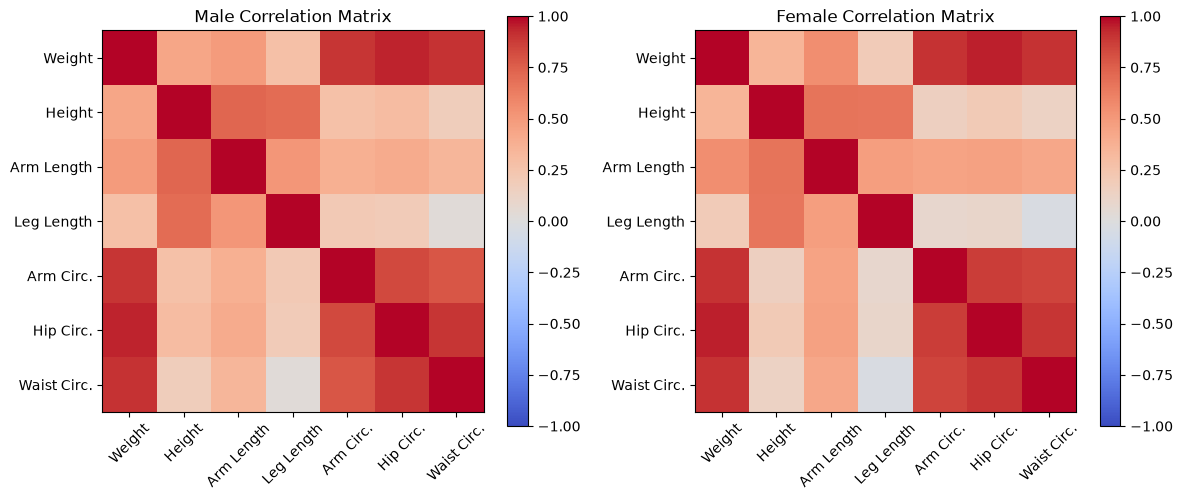

In [18]:
# Correlation heatmaps

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(male_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.title("Male Correlation Matrix")
plt.xticks(range(7), ["Weight", "Height", "Arm Length", "Leg Length",
                      "Arm Circ.", "Hip Circ.", "Waist Circ."], rotation=45)
plt.yticks(range(7), ["Weight", "Height", "Arm Length", "Leg Length",
                      "Arm Circ.", "Hip Circ.", "Waist Circ."])

plt.subplot(1, 2, 2)
plt.imshow(female_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.title("Female Correlation Matrix")
plt.xticks(range(7), ["Weight", "Height", "Arm Length", "Leg Length",
                      "Arm Circ.", "Hip Circ.", "Waist Circ."], rotation=45)
plt.yticks(range(7), ["Weight", "Height", "Arm Length", "Leg Length",
                      "Arm Circ.", "Hip Circ.", "Waist Circ."])

plt.tight_layout()
plt.show()

In [19]:
# Waist-to-height ratio
male_whr_height = male_clean[:, 6] / male_clean[:, 1]
female_whr_height = female_clean[:, 6] / female_clean[:, 1]

# Waist-to-hip ratio
male_whr_hip = male_clean[:, 6] / male_clean[:, 5]
female_whr_hip = female_clean[:, 6] / female_clean[:, 5]

print("Mean male waist-to-height ratio:", np.mean(male_whr_height))
print("Mean female waist-to-height ratio:", np.mean(female_whr_height))

print("\nMean male waist-to-hip ratio:", np.mean(male_whr_hip))
print("Mean female waist-to-hip ratio:", np.mean(female_whr_hip))

Mean male waist-to-height ratio: 0.5859832754903622
Mean female waist-to-height ratio: 0.6156169264982299

Mean male waist-to-hip ratio: 0.9708444312267365
Mean female waist-to-hip ratio: 0.8999790698583346


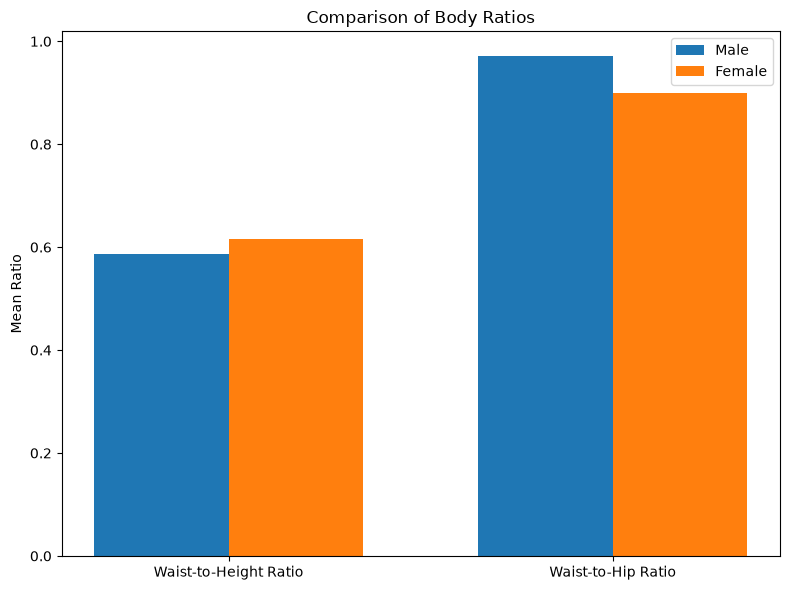

In [20]:
# Compare waist-to-height and waist-to-hip ratios

male_ratios = [
    np.mean(male_whr_height),
    np.mean(male_whr_hip)
]

female_ratios = [
    np.mean(female_whr_height),
    np.mean(female_whr_hip)
]

x = np.arange(2)
width = 0.35

plt.figure(figsize=(8, 6))

plt.bar(x - width/2, male_ratios, width, label="Male")
plt.bar(x + width/2, female_ratios, width, label="Female")

plt.xticks(x, ["Waist-to-Height Ratio", "Waist-to-Hip Ratio"])
plt.ylabel("Mean Ratio")
plt.title("Comparison of Body Ratios")
plt.legend()

plt.tight_layout()
plt.show()

### Interpretation

The mean waist-to-height ratio is approximately 0.586 for males and 0.616 for females. The mean waist-to-hip ratio is approximately 0.971 for males and 0.900 for females.

The results show that the female group has a higher average waist-to-height ratio, while the male group has a higher average waist-to-hip ratio. These ratios provide additional ways to compare body measurements between the two groups.

In [21]:
# Basic numerical aggregates of male and female weights

print("MALE WEIGHT STATISTICS")
print("Mean:", np.mean(male_clean[:, 0]))
print("Median:", np.median(male_clean[:, 0]))
print("Standard deviation:", np.std(male_clean[:, 0]))
print("Variance:", np.var(male_clean[:, 0]))
print("Minimum:", np.min(male_clean[:, 0]))
print("Maximum:", np.max(male_clean[:, 0]))
print("25th percentile:", np.percentile(male_clean[:, 0], 25))
print("75th percentile:", np.percentile(male_clean[:, 0], 75))

print("\nFEMALE WEIGHT STATISTICS")
print("Mean:", np.mean(female_clean[:, 0]))
print("Median:", np.median(female_clean[:, 0]))
print("Standard deviation:", np.std(female_clean[:, 0]))
print("Variance:", np.var(female_clean[:, 0]))
print("Minimum:", np.min(female_clean[:, 0]))
print("Maximum:", np.max(female_clean[:, 0]))
print("25th percentile:", np.percentile(female_clean[:, 0], 25))
print("75th percentile:", np.percentile(female_clean[:, 0], 75))

MALE WEIGHT STATISTICS
Mean: 88.36454300416565
Median: 85.0
Standard deviation: 21.418936717962495
Variance: 458.770850128082
Minimum: 36.8
Maximum: 204.6
25th percentile: 73.3
75th percentile: 99.8

FEMALE WEIGHT STATISTICS
Mean: 77.40379057095475
Median: 73.6
Standard deviation: 21.54250829019315
Variance: 464.07966343304065
Minimum: 32.6
Maximum: 180.9
25th percentile: 61.6
75th percentile: 88.7


### Interpretation of Weight Statistics

The mean weight is approximately 88.36 kg for males and 77.40 kg for females. The median weights are 85.0 kg for males and 73.6 kg for females, indicating that the male group generally has higher body weight.

The standard deviations are approximately 21.42 kg for males and 21.54 kg for females, showing that the spread of weights is quite similar in both groups. The male and female weight distributions also have similar variances.

The difference between the mean and median suggests some influence of higher-weight observations in both groups. Overall, the male group has a higher central weight, while both groups show considerable variation in weight.

In [22]:
# Add BMI as the 8th column of the female matrix

female_bmi_column = female[:, 0] / (female[:, 1] / 100) ** 2

female_with_bmi = np.column_stack((female, female_bmi_column))

print("Original female matrix shape:", female.shape)
print("New female matrix shape:", female_with_bmi.shape)

Original female matrix shape: (4222, 7)
New female matrix shape: (4222, 8)


In [23]:
# Standardise all columns of the female matrix

female_mean = np.nanmean(female_with_bmi, axis=0)
female_std = np.nanstd(female_with_bmi, axis=0)

zfemale = (female_with_bmi - female_mean) / female_std

print("Standardised female matrix shape:", zfemale.shape)

Standardised female matrix shape: (4222, 8)


In [24]:
# Select the standardised variables required for analysis

zfemale_selected = zfemale[:, [1, 0, 6, 5, 7]]

print("Selected variables shape:", zfemale_selected.shape)

Selected variables shape: (4222, 5)


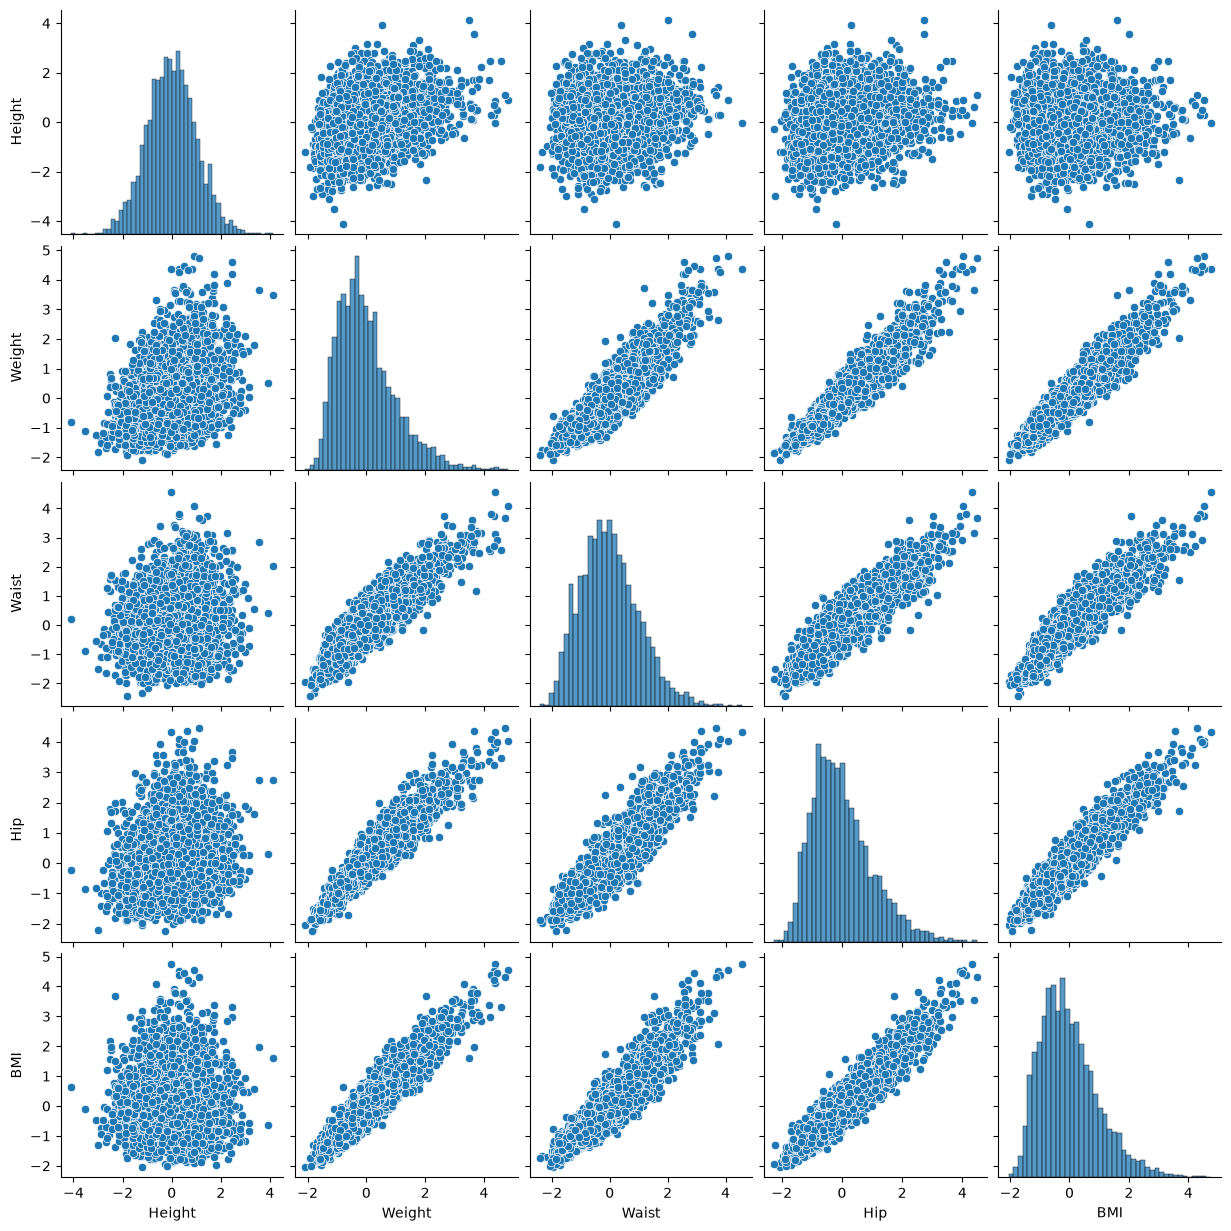

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

zfemale_df = pd.DataFrame(
    zfemale_selected,
    columns=["Height", "Weight", "Waist", "Hip", "BMI"]
)

sns.pairplot(zfemale_df)
plt.show()

In [26]:
# Pearson correlation matrix

pearson_corr = zfemale_df.corr(method="pearson")

print("Pearson Correlation Matrix:")
print(pearson_corr)

Pearson Correlation Matrix:
          Height    Weight     Waist       Hip       BMI
Height  1.000000  0.345496  0.126547  0.202895  0.033077
Weight  0.345496  1.000000  0.904550  0.946553  0.945900
Waist   0.126547  0.904550  1.000000  0.897407  0.921198
Hip     0.202895  0.946553  0.897407  1.000000  0.944199
BMI     0.033077  0.945900  0.921198  0.944199  1.000000


In [27]:
# Spearman correlation matrix

spearman_corr = zfemale_df.corr(method="spearman")

print("Spearman Correlation Matrix:")
print(spearman_corr)

Spearman Correlation Matrix:
          Height    Weight     Waist       Hip       BMI
Height  1.000000  0.338860  0.108587  0.205405  0.019897
Weight  0.338860  1.000000  0.900169  0.946634  0.937999
Waist   0.108587  0.900169  1.000000  0.888037  0.923114
Hip     0.205405  0.946634  0.888037  1.000000  0.934196
BMI     0.019897  0.937999  0.923114  0.934196  1.000000


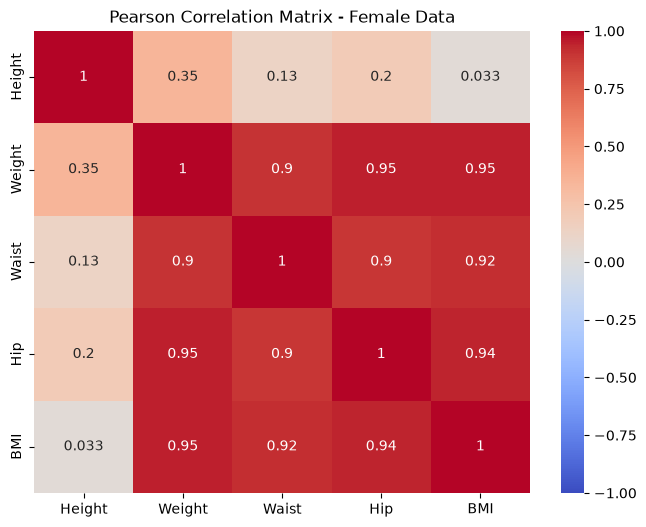

In [28]:
# Pearson correlation heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Correlation Matrix - Female Data")
plt.show()

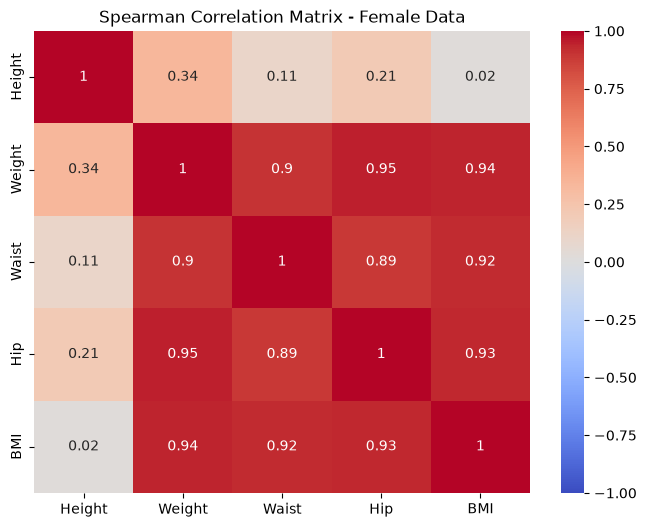

In [29]:
# Spearman correlation heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman Correlation Matrix - Female Data")
plt.show()

### Interpretation of Pearson and Spearman Correlations

The Pearson and Spearman correlation matrices show similar patterns. Weight has a very strong positive correlation with waist circumference, hip circumference, and BMI. The Pearson correlations are approximately 0.905 between Weight and Waist, 0.947 between Weight and Hip, and 0.946 between Weight and BMI.

Waist circumference also has a strong positive relationship with Hip circumference and BMI. Height has comparatively weak relationships with Waist and BMI.

The Spearman correlations show a similar pattern, with strong positive relationships between Weight, Waist, Hip, and BMI. The close similarity between the Pearson and Spearman results suggests that these relationships are consistently positive and strong in the female dataset.

In [30]:
# Calculate waist-to-height and waist-to-hip ratios

male_waist_height = male_clean[:, 6] / male_clean[:, 1]
male_waist_hip = male_clean[:, 6] / male_clean[:, 5]

female_waist_height = female_clean[:, 6] / female_clean[:, 1]
female_waist_hip = female_clean[:, 6] / female_clean[:, 5]

print("Male waist-to-height mean:", np.mean(male_waist_height))
print("Male waist-to-hip mean:", np.mean(male_waist_hip))
print("Female waist-to-height mean:", np.mean(female_waist_height))
print("Female waist-to-hip mean:", np.mean(female_waist_hip))

Male waist-to-height mean: 0.5859832754903622
Male waist-to-hip mean: 0.9708444312267365
Female waist-to-height mean: 0.6156169264982299
Female waist-to-hip mean: 0.8999790698583346


In [31]:
# Add waist-to-height and waist-to-hip ratios to the matrices

male_with_ratios = np.column_stack(
    (male_clean, male_waist_height, male_waist_hip)
)

female_with_ratios = np.column_stack(
    (female_clean, female_waist_height, female_waist_hip)
)

print("Male matrix shape:", male_with_ratios.shape)
print("Female matrix shape:", female_with_ratios.shape)

Male matrix shape: (4081, 9)
Female matrix shape: (4221, 9)


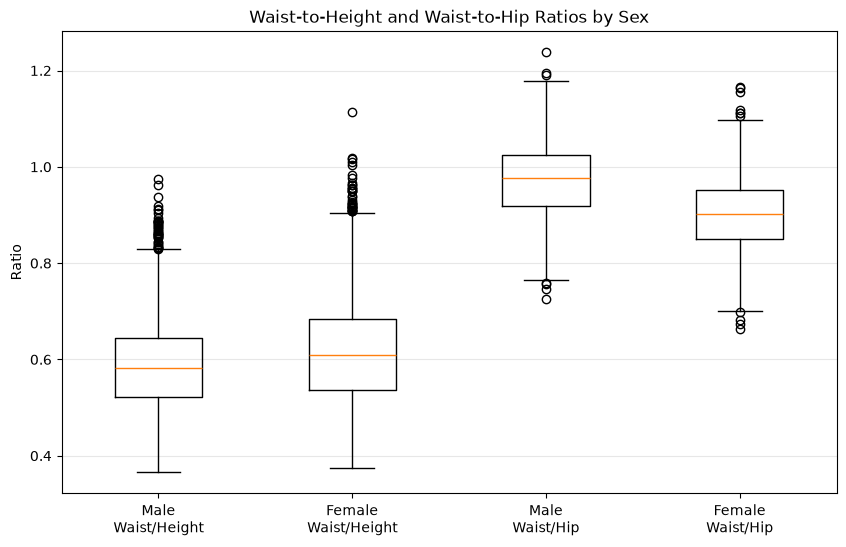

In [32]:
# Four-box comparison of waist-to-height and waist-to-hip ratios

plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        male_waist_height,
        female_waist_height,
        male_waist_hip,
        female_waist_hip
    ],
    tick_labels=[
        "Male\nWaist/Height",
        "Female\nWaist/Height",
        "Male\nWaist/Hip",
        "Female\nWaist/Hip"
    ]
)

plt.title("Waist-to-Height and Waist-to-Hip Ratios by Sex")
plt.ylabel("Ratio")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Interpretation of Waist-to-Height and Waist-to-Hip Ratios

The boxplot compares waist-to-height and waist-to-hip ratios between males and females.

The female group has a higher mean waist-to-height ratio than the male group, while the male group has a higher mean waist-to-hip ratio. The boxplots also show the variation and spread of these ratios within each group. The position of the median and the length of the boxes and whiskers indicate differences in the distribution of the ratios between males and females.

Overall, waist-to-height and waist-to-hip ratios provide additional measures for comparing body proportions between the two groups.

### Advantages and Disadvantages of BMI, Waist-to-Height Ratio and Waist-to-Hip Ratio

#### BMI

**Advantages:**
- BMI is simple and quick to calculate using height and weight.
- It provides a standardised measure that can be used to compare large groups of people.
- It is widely used in health and population studies.

**Disadvantages:**
- BMI does not distinguish between muscle mass and body fat.
- It does not show where fat is distributed in the body.
- It may not accurately represent body composition for every individual.

#### Waist-to-Height Ratio

**Advantages:**
- It considers waist circumference in relation to height.
- It provides an indication of central fat distribution.
- It is simple to calculate and easy to interpret.

**Disadvantages:**
- It depends on accurate measurements of both waist and height.
- It does not directly measure total body fat.
- The appropriate interpretation can vary between populations.

#### Waist-to-Hip Ratio

**Advantages:**
- It provides information about the distribution of body measurements between the waist and hips.
- It can be used to compare body proportions between groups.
- It is relatively simple to calculate.

**Disadvantages:**
- It requires two separate circumference measurements.
- Changes in hip circumference can affect the ratio even when waist circumference remains unchanged.
- It does not directly measure total body fat or body composition.

Overall, BMI, waist-to-height ratio and waist-to-hip ratio provide different information. Using more than one measure can provide a broader understanding of body size and body proportions than relying on a single measure.

In [35]:
# Find the 5 lowest and 5 highest valid BMI values

valid_bmi_indices = np.where(~np.isnan(female_with_bmi[:, 7]))[0]

sorted_indices = valid_bmi_indices[
    np.argsort(female_with_bmi[valid_bmi_indices, 7])
]

lowest_5_indices = sorted_indices[:5]
highest_5_indices = sorted_indices[-5:][::-1]

print("5 lowest BMI indices:")
print(lowest_5_indices)

print("\n5 highest BMI indices:")
print(highest_5_indices)

5 lowest BMI indices:
[ 263 3479 2127 2754 1210]

5 highest BMI indices:
[1097 1105 1473 3023 2269]


In [36]:
# Print standardised measurements for the valid BMI groups

print("STANDARDISED MEASUREMENTS - 5 LOWEST BMI FEMALES")
print(zfemale[lowest_5_indices])

print("\nSTANDARDISED MEASUREMENTS - 5 HIGHEST BMI FEMALES")
print(zfemale[highest_5_indices])

STANDARDISED MEASUREMENTS - 5 LOWEST BMI FEMALES
[[-2.07978523 -1.22299143 -1.5478402  -1.16905675 -2.1947611  -2.0405496
  -1.94212128 -2.05024028]
 [-1.88017988 -0.18929313 -1.71835247  0.38637892 -2.4443617  -1.85491922
  -2.05708015 -1.99487987]
 [-1.53667299  1.80730222  0.62619127  0.5730312  -2.26607556 -1.6756899
  -1.7064556  -1.97088383]
 [-1.843044   -0.26009438 -0.22637009  0.51081377 -2.30173278 -2.25178417
  -1.85590213 -1.94177591]
 [-1.61094475  0.88688592 -0.09848588  0.47970506 -2.21258971 -1.82931504
  -1.71220354 -1.89319577]]

STANDARDISED MEASUREMENTS - 5 HIGHEST BMI FEMALES
[[ 4.36328993 -0.03353037 -0.05585782 -0.17357792  2.77942222  4.31569054
   4.57029862  4.76243308]
 [ 4.8042785   0.88688592  2.11817365  1.81737973  3.77782461  4.02124236
   4.08172343  4.54270932]
 [ 4.34936397  0.27799514  2.84285081  1.94181459  4.36616887  3.9188256
   3.75409065  4.51466896]
 [ 4.45612963  0.50455915  1.69189297 -1.13794804  3.34993787  3.98283607
   2.90339503  4.462

### Interpretation of the 5 Lowest and 5 Highest BMI Females

The standardised measurements show a clear difference between the females with the lowest and highest BMI values.

The five females with the lowest BMI generally have negative standardised BMI scores, indicating that their BMI values are below the female group average. Their height, weight and circumference measurements also tend to be below the corresponding group averages.

In contrast, the five females with the highest BMI have strongly positive standardised BMI scores. Their weight, waist and hip measurements are generally substantially above the female group averages. Some of their other measurements also show positive standardised values.

This comparison demonstrates how standardisation can be used to identify observations that are relatively low or high compared with the overall female population. The results also show that higher BMI is generally associated with higher weight, waist circumference and hip circumference in this dataset.